# Legislative coverage in Costa Rican news: reproducing the main numbers

This notebook uses only the public corpus in this folder (`cr_legislative_coverage.zip`). It checks the file,
opens the SQLite database and recomputes the figures reported by the project: the size of each pipeline stage,
coverage by outlet and over time, which bills reached the news, and how the model's links compare with the links
that outlets make themselves. Table and column descriptions: `README.md`. Requirements: `pandas`, `matplotlib`.

In [1]:
import hashlib
import sqlite3
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ZIP = Path("cr_legislative_coverage.zip")
DB = Path("cr_legislative_coverage.db")

# Expected checksums, as published in SHA256SUMS.
expected = dict(reversed(line.split()) for line in Path("SHA256SUMS").read_text().splitlines())

def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

assert sha256(ZIP) == expected[ZIP.name], "the zip does not match SHA256SUMS"
if not DB.exists() or sha256(DB) != expected[DB.name]:
    with zipfile.ZipFile(ZIP) as archive:
        archive.extract(DB.name)
assert sha256(DB) == expected[DB.name]

con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)
q = lambda sql: pd.read_sql(sql, con)
pd.set_option("display.max_colwidth", 90)
q("SELECT key, value FROM corpus_info WHERE key NOT LIKE 'rows.%'")

,key,value
0,built_utc,2026-11-16T04:53:52+00:00
1,news_period,2026-05-01 / 2026-10-31
2,jev_models,jev-1.14.0
3,jev_match_threshold,0.5
4,mention_rule,jev_match and (explicit >= 0.5 or implicit >= 0.75)
5,substantive_rule,mention and centrality >= 0.25
6,max_news_chars,15000
7,license,CC BY 4.0 (see LICENSE)


## 1. Pipeline: from 29,875 news items to 3,462 substantive links

Every news item with text goes through Jev's filter (is it about the Asamblea?). For those that pass, the ranker
proposes 50 candidate bills and Jev's gate decides which ones the item covers. A **mention** needs a clear
explicit or implicit answer. A **substantive** link also needs centrality >= 0.25.

In [2]:
funnel = q("""
SELECT 'news items collected' AS stage, COUNT(*) AS n FROM news_articles
UNION ALL SELECT 'with text, sent to the filter', COUNT(*) FROM jev_filter
UNION ALL SELECT 'pass the filter (assembly >= 0.2)', SUM(passes) FROM jev_filter
UNION ALL SELECT 'candidate pairs (news x bill)', COUNT(*) FROM jev_candidates
UNION ALL SELECT 'pairs matched by Jev', SUM(jev_match) FROM links
UNION ALL SELECT 'pairs at mention level', SUM(mention) FROM links
UNION ALL SELECT 'pairs at substantive level', SUM(substantive) FROM links
UNION ALL SELECT 'news items with a substantive link', COUNT(DISTINCT news_id) FROM links WHERE substantive
UNION ALL SELECT 'bills with a substantive link', COUNT(DISTINCT bill_number) FROM links WHERE substantive
""")
funnel

,stage,n
0,news items collected,29875
1,"with text, sent to the filter",29698
2,pass the filter (assembly >= 0.2),7431
3,candidate pairs (news x bill),371876
4,pairs matched by Jev,6329
5,pairs at mention level,4671
6,pairs at substantive level,3462
7,news items with a substantive link,2620
8,bills with a substantive link,570


## 2. Coverage by outlet

In [3]:
outlets = q("""
SELECT n.organization AS outlet, n.outlet_type,
       COUNT(*) AS news,
       SUM(f.passes) AS about_assembly,
       SUM(n.id IN (SELECT news_id FROM links WHERE substantive)) AS with_substantive_link
FROM news_articles n
LEFT JOIN jev_filter f ON f.news_id = n.id
GROUP BY n.organization, n.outlet_type
ORDER BY news DESC
""")
outlets["share_linked_%"] = (100 * outlets.with_substantive_link / outlets.news).round(1)
outlets

,outlet,outlet_type,news,about_assembly,with_substantive_link,share_linked_%
0,crhoy,general,9442,1602,547,5.8
1,nacion,general,9424,2061,640,6.8
2,delfino,specialized,5399,1327,645,11.9
3,elmundo,general,3388,1481,361,10.7
4,semanario,general,2222,960,427,19.2


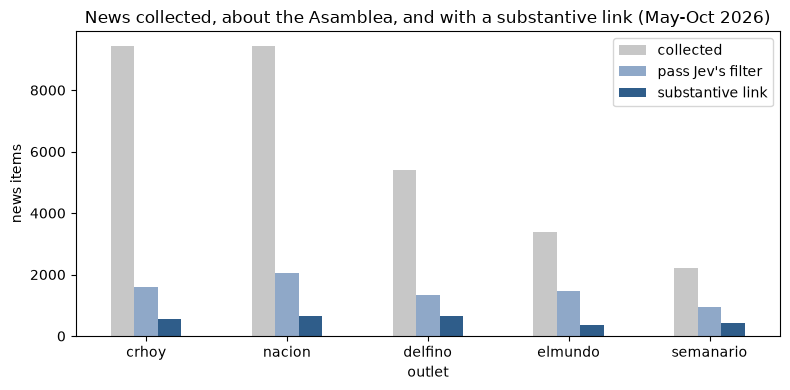

In [4]:
ax = outlets.set_index("outlet")[["news", "about_assembly", "with_substantive_link"]].plot.bar(
    figsize=(8, 4), rot=0, color=["#c7c7c7", "#8fa8c8", "#2f5d8a"])
ax.set_ylabel("news items")
ax.set_title("News collected, about the Asamblea, and with a substantive link (May-Oct 2026)")
ax.legend(["collected", "pass Jev's filter", "substantive link"])
plt.tight_layout()

Delfino specializes in the Asamblea, so it is reported apart from the four general outlets. The project does
not rank outlets: with 12–19 labeled positives per outlet, the evaluation sample cannot tell them apart.

## 3. Coverage over time

outlet,crhoy,delfino,elmundo,nacion,semanario
month,,,,,
2026-05,97,137,88,149,83
2026-06,104,111,57,118,91
2026-07,92,116,43,102,98
2026-08,99,186,63,146,90
2026-09,127,157,68,129,109
2026-10,142,287,98,161,114


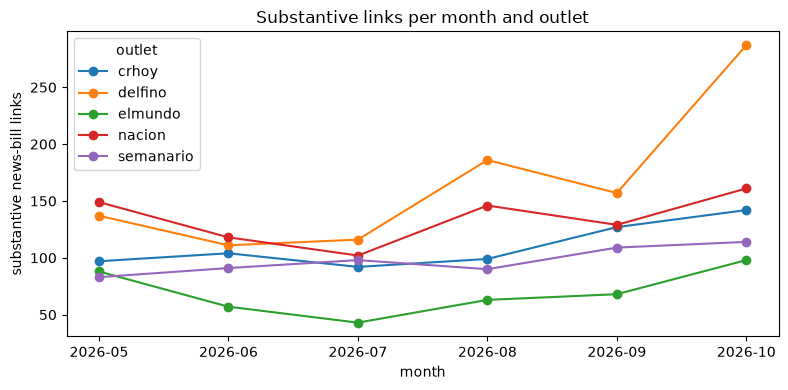

In [5]:
monthly = q("""
SELECT substr(n.date_published, 1, 7) AS month, n.organization AS outlet, COUNT(*) AS substantive_links
FROM links l JOIN news_articles n ON n.id = l.news_id
WHERE l.substantive
GROUP BY month, outlet
""").pivot(index="month", columns="outlet", values="substantive_links").fillna(0).astype(int)
ax = monthly.plot(figsize=(8, 4), marker="o")
ax.set_ylabel("substantive news-bill links")
ax.set_title("Substantive links per month and outlet")
plt.tight_layout()
monthly

## 4. Which bills reach the news

The comparable universe is the set of bills with activity in the period: filed, or with a step of their
procedure between May 1 and October 31, 2026. (The site also counts votes as activity, but the votes come from
Delfino and are not part of the corpus.)

In [6]:
bills = q("""
WITH active AS (
  SELECT number FROM bills WHERE date_proposed BETWEEN '2026-05-01' AND '2026-10-31T99'
  UNION SELECT number FROM bill_steps
  WHERE date_start BETWEEN '2026-05-01' AND '2026-10-31T99' OR date_end BETWEEN '2026-05-01' AND '2026-10-31T99'),
covered AS (
  SELECT bill_number AS number, COUNT(DISTINCT news_id) AS news FROM links WHERE substantive GROUP BY bill_number)
SELECT b.number, b.name, b.status, b.number IN (SELECT number FROM active) AS active, COALESCE(c.news, 0) AS news
FROM bills b LEFT JOIN covered c ON c.number = b.number
""")
active = bills[bills.active == 1]
summary = pd.Series({
    "bills in the SIL table": len(bills),
    "bills with activity in the period": len(active),
    "active bills with a substantive link": int((active.news > 0).sum()),
    "share of active bills covered (%)": round(100 * (active.news > 0).mean(), 1),
    "bills covered that had no activity": int(((bills.active == 0) & (bills.news > 0)).sum()),
})
summary

bills in the SIL table                  5898.0
bills with activity in the period        929.0
active bills with a substantive link     374.0
share of active bills covered (%)         40.3
bills covered that had no activity       196.0
dtype: float64

In [7]:
by_status = bills[bills.active == 1].groupby("status").agg(
    active=("number", "size"), covered=("news", lambda s: int((s > 0).sum())))
by_status["covered_%"] = (100 * by_status.covered / by_status.active).round(1)
by_status

,active,covered,covered_%
status,,,
archived,236,30,12.7
in progress,597,303,50.8
law,96,41,42.7


570 bills have a substantive link; 35 of them account for half of the links (6.1%).


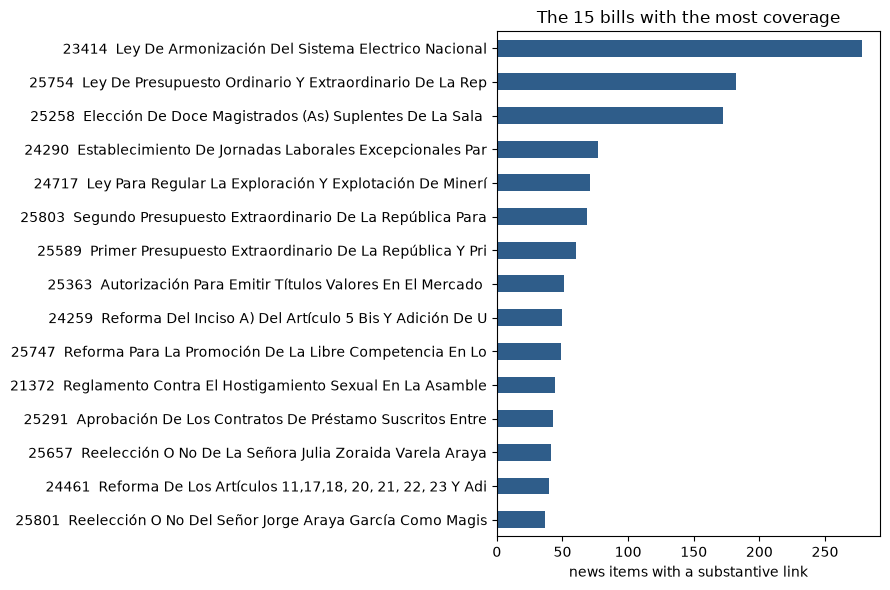

In [8]:
covered = bills[bills.news > 0].sort_values("news", ascending=False)
cumulative = covered.news.cumsum() / covered.news.sum()
half = int((cumulative < 0.5).sum()) + 1
print(f"{len(covered)} bills have a substantive link; {half} of them account for half of the links "
      f"({100 * half / len(covered):.1f}%).")

top = covered.head(15).assign(label=lambda d: d.number.astype(str) + "  " + d.name.str.slice(0, 55).str.title())
ax = top.iloc[::-1].plot.barh(x="label", y="news", figsize=(9, 6), legend=False, color="#2f5d8a")
ax.set_xlabel("news items with a substantive link")
ax.set_ylabel("")
ax.set_title("The 15 bills with the most coverage")
plt.tight_layout()

## 5. Model links vs. the links outlets make

Delfino links some of its news items to the bill's page. Those 1,425 links were never shown to Jev, so they work
as an outside check: how many of them did the pipeline find at each level?

In [9]:
q("""
SELECT COUNT(*) AS outlet_links,
       SUM(jev_match) AS found_by_jev,
       ROUND(100.0 * SUM(jev_match) / COUNT(*), 1) AS jev_match_pct,
       ROUND(100.0 * SUM(mention) / COUNT(*), 1) AS mention_pct,
       ROUND(100.0 * SUM(substantive) / COUNT(*), 1) AS substantive_pct
FROM links WHERE outlet_link
""")

,outlet_links,found_by_jev,jev_match_pct,mention_pct,substantive_pct
0,1425,1336,93.8,93.2,52.7


## 6. What stage of the procedure the news reports

For each substantive pair, Jev chose the stage of the procedure that the news item reports.

In [10]:
stage = q("""
SELECT d.choice AS stage, COUNT(*) AS pairs
FROM (SELECT DISTINCT news_id, bill_number, choice FROM jev_details WHERE question = 'stage' AND choice IS NOT NULL) d
JOIN links l ON l.news_id = d.news_id AND l.bill_number = d.bill_number AND l.substantive
GROUP BY d.choice ORDER BY pairs DESC
""")
stage["%"] = (100 * stage.pairs / stage.pairs.sum()).round(1)
stage

,stage,pairs,%
0,not_stated,1010,29.2
1,filing,797,23.0
2,committee,575,16.6
3,first_debate,367,10.6
4,second_debate,224,6.5
5,archived_or_rejected,205,5.9
6,veto_or_signing,182,5.3
7,constitutional_court,102,2.9


In [11]:
con.close()